# 병렬 섹셔닝과 투표

**이 노트북에서 할 일**

1. 서로 기다릴 필요가 없는 요청 셋을 하나씩 보낸 때와 함께 보낸 때를 견줍니다.
2. 함께 받은 답 목록의 차례와, 기록 줄이 쌓인 차례를 나란히 봅니다.
3. 공통 사실 하나를 부분 셋으로 나눠 쓰는 흐름을 함수로 만듭니다.
4. 같은 두 글을 평가자 셋에게 함께 보내 표를 세고, 필요한 표 수로 결과를 정합니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청은 노트북 한 번에 열두 번입니다.
4절, 5절, 6절, 8절에서 세 번씩 나갑니다.

토큰 수를 출력하는 요청은 열두 번 가운데 여섯 번입니다.
나머지 요청도 같은 크기로 보고 요금표를 곱해 어림한 예상 비용은 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

자료 파일을 읽거나 새 파일을 쓰지 않습니다.
01절에서 배운 함수 둘은 같은 폴더의 도구 파일 `workflow_tools.py`에서 가져옵니다.
이 절은 걸린 시간을 잽니다. 잰 초는 기기·네트워크·실행 때에 따라 달라집니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 10초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 openai 2.29.0과 python-dotenv 1.2.3을 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~5절을 읽습니다.
요청 셋을 하나씩 보낸 때와 함께 보낸 때를 견주는 자리입니다.
6~9절은 나눠 쓰기와 투표를 함수로 만들어 실행하는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch18-workflow-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![칸 둘이 나란히 있고 아래에 회색 상자가 있는 그림으로 왼쪽 나눠 쓰기 write_sections 칸에서는 초록 상자 지시 글 하나 요청 글 셋 공통 사실과 쓸 부분 목적 절차 문의가 보라 상자 gpt-5.4-mini 요청 셋을 함께 보냄을 지나 노란 상자 부분 글 셋을 넣은 차례로 이은 안내문으로 이어지고 오른쪽 투표 run_vote 칸에서는 초록 상자 지시 글 셋 요청 글 하나 평가자 셋과 후보 A와 B가 보라 상자 gpt-5.4-mini 요청 셋을 함께 보냄을 지나 노란 상자 표 셋 A A B 필요한 표 수 2의 결과 A로 이어지며 맨 아래 회색 상자에 두 칸 모두 ask_all_together asyncio.to_thread와 asyncio.gather가 적힌 그림](attachment:03-1-나눠-쓰기와-투표.png)

칸 둘은 이 절의 두 흐름입니다. 두 칸 모두 보라 상자에서 요청 셋을 함께 보냅니다.
다른 것은 맨 위 초록 상자입니다. 나눠 쓰기는 요청 글이 셋이고, 투표는 지시 글이 셋입니다.
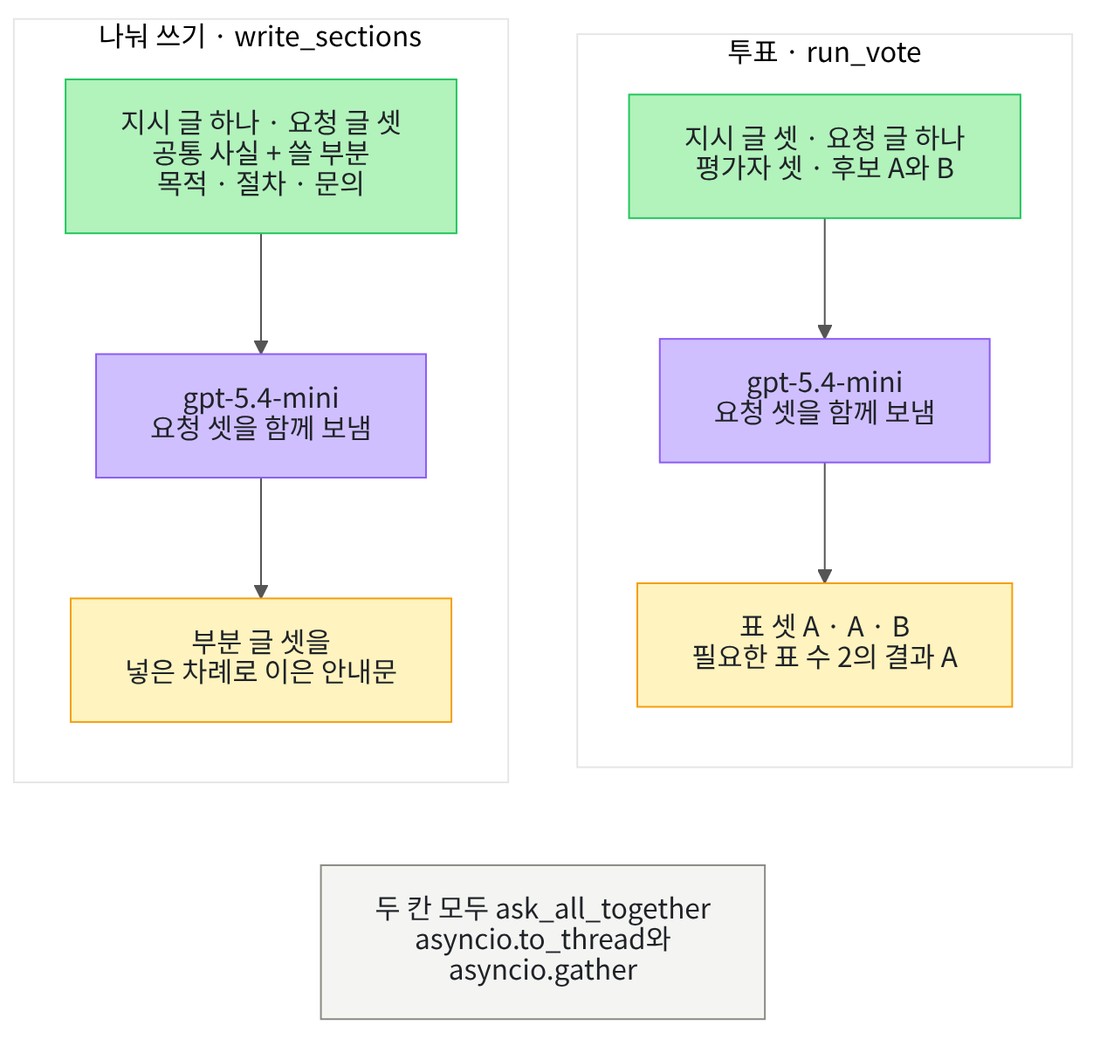

## 1. 준비

제목의 섹셔닝(sectioning)은 이 절에서 「나눠 쓰기」라고 부릅니다.
공통 사실 하나로 글의 부분 여럿을 요청마다 따로 쓰게 하는 모양입니다.

나눠 쓰기와 투표는 모두 모델 요청 여러 개를 함께 보내는 방식입니다.
이 절은 그 방식을 「함께 보내기(parallelization)」라고 부릅니다.
제목의 병렬이 이 말입니다.

첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "openai==2.29.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


openai: 2.29.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `openai: 2.29.0`과 `python-dotenv: 1.2.3`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `workflow_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
다음 셀은 Ch 2 12절에서 쓴 모듈 둘과, 01절에서 배운 함수 둘을 가져옵니다.

In [2]:
# 함께 기다리는 모듈 asyncio와 시간을 재는 모듈 time, 클라이언트 이름 OpenAI와 01절 함수 둘을 가져옵니다
import asyncio
import time

from openai import OpenAI

from workflow_tools import ask_json, print_records

print("불러온 이름:", "asyncio", "time", "OpenAI", "ask_json", "print_records")

불러온 이름: asyncio time OpenAI ask_json print_records


**결과 읽기** — 출력 줄 `불러온 이름: asyncio time OpenAI ask_json print_records`로 이름 다섯을 가져왔습니다.
모듈 `asyncio`는 요청을 함께 기다릴 때, 모듈 `time`은 걸린 시간을 잴 때 씁니다.
함수 `ask_json`은 요청 한 번을 보내 기록 한 줄을 남기고, 받은 JSON 글을 딕셔너리로 내놓습니다.
함수 `print_records`는 기록 목록을 번호·단계·입력 토큰·출력 토큰 차례로 출력합니다.

## 2. 키와 클라이언트 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`로 키를 찾았습니다.
키 값은 출력하지 않습니다.

다음 셀은 01절처럼 `client = OpenAI()` 한 줄로 클라이언트를 만듭니다.
이 절은 이 클라이언트 하나를 여러 스레드가 함께 씁니다.
스레드(thread)는 Ch 2 12절에서 본, 한 프로그램 안에서 따로 진행되는 실행 흐름입니다.

In [4]:
# OpenAI 서비스에 요청을 보낼 클라이언트를 하나 만듭니다(키는 앞 셀에서 읽은 환경 변수를 씁니다)
client = OpenAI()
print("클라이언트:", type(client).__name__)

클라이언트: OpenAI


**결과 읽기** — 출력 줄 `클라이언트: OpenAI`로 클라이언트를 만들었습니다.
이 클라이언트는 HTTP 연결을 맡는 httpx 라이브러리의 클라이언트를 안에 둡니다.
설치한 httpx 0.28.1의 설명은 그 클라이언트를 여러 스레드가 함께 써도 된다고 적습니다.
노트북 밖에서도 이 클라이언트 하나로 요청 열 개를 함께 보내 보았고, 두 번 모두 제 답을 받았습니다.

## 3. 나눠 쓸 재료 — 공통 사실과 부분 셋

사내 안내문 하나를 목적·절차·문의 세 부분으로 나눠 씁니다.
세 부분은 같은 공통 사실만 있으면 되고, 다른 부분의 글을 기다리지 않아도 됩니다.
다음 셀은 세 부분이 함께 쓸 공통 사실을 적습니다.

In [5]:
# 세 부분이 함께 쓸 공통 사실을 적습니다(날짜·까닭·등록 방법·문의처)
notice_fact = "2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. "
notice_fact = notice_fact + "비밀번호만으로는 계정을 지키기 어렵기 때문입니다. "
notice_fact = notice_fact + "등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. "
notice_fact = notice_fact + "문의는 help@company.test로 받습니다."
print("공통 사실:")
print(notice_fact)

공통 사실:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.


**결과 읽기** — 라벨 줄 `공통 사실:` 아래 한 줄이 공통 사실입니다.
날짜, 까닭, 등록 방법, 문의처가 한 문장씩 들어 있습니다.
문의처 `help@company.test`는 연습용 주소입니다.

다음 셀은 부분 하나를 쓰는 작성자의 지시 글입니다.
세 부분의 요청은 이 지시 글 하나를 함께 씁니다.

In [6]:
# 부분 하나를 쓰는 작성자의 지시 글을 적습니다: 공통 사실에 없는 것은 지어내지 않게 합니다
write_instructions = "사내 안내문의 한 부분을 쓰는 작성자입니다. "
write_instructions = write_instructions + "공통 사실 가운데 쓸 부분에 맞는 것만 골라 한국어 두 문장으로 씁니다. "
write_instructions = write_instructions + "공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. "
# 칸 「부분」에는 부분 이름을 그대로 적게 해, 받은 답이 어느 부분의 답인지 알아볼 수 있게 합니다
write_instructions = write_instructions + '답은 JSON 객체 하나로만 출력합니다: {"부분": "쓸 부분 이름 그대로", "글": "글"}'
print("지시 글:")
print(write_instructions)

지시 글:
사내 안내문의 한 부분을 쓰는 작성자입니다. 공통 사실 가운데 쓸 부분에 맞는 것만 골라 한국어 두 문장으로 씁니다. 공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. 답은 JSON 객체 하나로만 출력합니다: {"부분": "쓸 부분 이름 그대로", "글": "글"}


**결과 읽기** — 라벨 줄 `지시 글:` 아래 한 줄이 작성자의 지시 글입니다.
끝에 답 모양 `{"부분": "쓸 부분 이름 그대로", "글": "글"}`을 적었습니다.
칸 「부분」은 받은 답이 어느 부분의 답인지 알아보려고 둔 칸입니다.

다음 셀은 요청 글을 만드는 함수입니다.
요청 머리글과 공통 사실 뒤에, 쓸 부분의 이름과 담을 내용을 붙입니다.

In [7]:
# 요청 머리글과 공통 사실 뒤에, 쓸 부분의 이름과 담을 내용을 붙여 요청 글 하나를 만듭니다
def build_part_request(request_head, fact, part):
    part_lines = "\n쓸 부분: " + part["이름"] + "\n담을 내용: " + part["담을 내용"]
    return request_head + fact + part_lines

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_part_request`는 요청 머리글, 공통 사실, 부분 딕셔너리 하나를 받습니다.
부분 딕셔너리에는 칸 「이름」과 「담을 내용」이 있습니다.
받은 셋을 차례로 이어 요청 글 하나를 내놓습니다.

다음 셀은 부분 셋을 적고, 부분마다 요청 글을 만듭니다.
요청 머리글에는 JSON이라는 말을 넣습니다.
02절에서 본 것처럼, 형식 `json_object`는 요청 글에 그 말이 있어야 하기 때문입니다.

In [8]:
# 부분 셋을 적고, 부분마다 요청 글을 하나씩 만듭니다(머리글에 JSON이라는 말을 넣습니다)
request_head = "아래 공통 사실로 안내문의 한 부분을 JSON으로 쓰세요.\n공통 사실: "
purpose_part = {"이름": "목적", "담을 내용": "적용 날짜와 까닭"}
steps_part = {"이름": "절차", "담을 내용": "직원이 할 일"}
contact_part = {"이름": "문의", "담을 내용": "물어볼 곳"}
purpose_request = build_part_request(request_head, notice_fact, purpose_part)
steps_request = build_part_request(request_head, notice_fact, steps_part)
contact_request = build_part_request(request_head, notice_fact, contact_part)
print("목적 부분의 요청 글:")
print(purpose_request)

목적 부분의 요청 글:
아래 공통 사실로 안내문의 한 부분을 JSON으로 쓰세요.
공통 사실: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.
쓸 부분: 목적
담을 내용: 적용 날짜와 까닭


**결과 읽기** — 라벨 줄 `목적 부분의 요청 글:` 아래 네 줄이 목적 부분의 요청 글입니다.
첫 줄은 요청 머리글이고, 둘째 줄은 공통 사실입니다.
마지막 두 줄 `쓸 부분: 목적`과 `담을 내용: 적용 날짜와 까닭`만 부분마다 다릅니다.
세 요청 글은 서로의 답을 넣지 않으므로, 어느 것을 먼저 보내도 됩니다.

## 4. 하나씩 보내기

먼저 01·02절처럼 요청 셋을 하나씩 보냅니다.
함수 `ask_json`은 응답이 올 때까지 그 줄에서 기다리는 동기 함수입니다.
그래서 둘째 요청은 첫 응답을 받은 뒤에야 나갑니다.
걸린 시간은 Ch 2 12절처럼 `time.perf_counter()`로 잽니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [9]:
# 세 요청을 하나씩 보내고, 셋이 모두 끝날 때까지 걸린 초를 잽니다(모델 요청 3번)
one_by_one_records = []
start_time = time.perf_counter()
purpose_answer = ask_json(client, one_by_one_records, "목적", write_instructions, purpose_request)
steps_answer = ask_json(client, one_by_one_records, "절차", write_instructions, steps_request)
contact_answer = ask_json(client, one_by_one_records, "문의", write_instructions, contact_request)
# 끝난 뒤 시각에서 시작 시각을 빼면 걸린 초입니다
elapsed = time.perf_counter() - start_time
one_by_one_seconds = round(elapsed, 3)
print("받은 답의 칸 「부분」:", purpose_answer["부분"], steps_answer["부분"], contact_answer["부분"])
print("하나씩 보낸 걸린 초:", one_by_one_seconds)

받은 답의 칸 「부분」: 목적 절차 문의
하나씩 보낸 걸린 초: 4.751


**결과 읽기** — 출력 줄 `받은 답의 칸 「부분」: 목적 절차 문의`로 세 답이 제 부분에 맞게 왔습니다.
세 요청은 앞 요청이 끝난 뒤에 차례로 나갔습니다.

출력 줄 `하나씩 보낸 걸린 초:` 뒤 수는 실행마다 달라집니다.
교재 출력에서는 `하나씩 보낸 걸린 초: 4.751`이었습니다.

다음 셀은 세 요청의 기록 줄을 출력합니다.

In [10]:
# 하나씩 보낸 세 요청의 기록 줄을 출력합니다
print("요청 수(기록 줄 수):", len(one_by_one_records))
print_records(one_by_one_records)

요청 수(기록 줄 수): 3
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 목적 | 196 | 54
2 | 절차 | 195 | 70
3 | 문의 | 194 | 57


**결과 읽기** — 출력 줄 `요청 수(기록 줄 수): 3`으로 요청이 세 번 나갔습니다.
라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 세 줄은 목적·절차·문의 차례입니다.
하나씩 보냈으므로 기록 줄도 보낸 차례대로 쌓였습니다.
입력 토큰은 `1 | 목적 | 196`, `2 | 절차 | 195`, `3 | 문의 | 194`입니다.

출력 토큰은 모델이 쓴 글의 길이라 실행마다 달라질 수 있습니다.

## 5. 함께 보내기 — asyncio.to_thread()와 gather()

이번에는 같은 세 요청을 함께 보냅니다.
Ch 2 12절 After에서는 동기 함수를 `asyncio.to_thread()`로 다른 스레드에서 불렀습니다.
여기서도 함수 `ask_json`은 고치지 않고, 부르는 모양만 바꿉니다.
괄호에는 함수 이름 `ask_json`을 괄호 없이 넣고, 그 뒤에 인자를 차례로 넣습니다.
다음 셀은 코루틴 셋을 만들기만 하고 아직 요청을 보내지 않습니다.

In [11]:
# 같은 세 요청을 asyncio.to_thread()로 감싸 코루틴 셋을 만듭니다(부르기만 해서 아직 보내지 않습니다)
together_records = []
# to_thread(함수, 인자들)는 그 함수를 다른 스레드에서 부르는 코루틴을 내놓습니다
purpose_waiting = asyncio.to_thread(ask_json, client, together_records, "목적", write_instructions, purpose_request)
steps_waiting = asyncio.to_thread(ask_json, client, together_records, "절차", write_instructions, steps_request)
contact_waiting = asyncio.to_thread(ask_json, client, together_records, "문의", write_instructions, contact_request)
print("만든 값의 자료형:", type(purpose_waiting).__name__)
print("쌓인 기록 줄 수:", len(together_records))

만든 값의 자료형: coroutine
쌓인 기록 줄 수: 0


**결과 읽기** — 출력 줄 `만든 값의 자료형: coroutine`으로 코루틴이 만들어졌습니다.
출력 줄 `쌓인 기록 줄 수: 0`으로 요청은 아직 하나도 나가지 않았습니다.
Ch 2 12절처럼 코루틴은 부르기만 해서는 실행되지 않습니다.
세 코루틴은 기록 목록 `together_records` 하나를 함께 씁니다.

다음 셀은 코루틴 셋을 함수 `asyncio.gather()`에 함께 넣고 await로 기다립니다.
Ch 2 12절처럼 변수 셋을 괄호에 직접 넣습니다.
셀 맨 위에 await 줄을 바로 쓰는 것은 노트북 도구(IPython)의 기능입니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [12]:
# 코루틴 셋을 gather()에 함께 넣어, 세 요청이 모두 끝날 때까지 함께 기다립니다(모델 요청 3번)
start_time = time.perf_counter()
together_answers = await asyncio.gather(purpose_waiting, steps_waiting, contact_waiting)
elapsed = time.perf_counter() - start_time
together_seconds = round(elapsed, 3)
print("받은 답 수:", len(together_answers))
print("함께 기다린 걸린 초:", together_seconds)

받은 답 수: 3
함께 기다린 걸린 초: 1.667


**결과 읽기** — 출력 줄 `받은 답 수: 3`으로 세 답을 목록 하나로 받았습니다.
세 요청을 보낸 뒤 셋의 응답을 함께 기다렸고, 함수 `gather()`는 셋이 모두 끝난 뒤 목록을 내놓았습니다.

출력 줄 `함께 기다린 걸린 초:` 뒤 수도 실행마다 달라집니다.
교재 출력에서는 `함께 기다린 걸린 초: 1.667`이었습니다.

한 번 기다린 코루틴은 다시 기다릴 수 없어, 이 셀만 다시 실행하면 `RuntimeError`로 멈춥니다.
다시 실행하려면 코루틴을 만드는 앞 셀부터 다시 실행합니다.

다음 셀은 받은 답 목록의 차례와, 기록 줄이 쌓인 차례를 나란히 봅니다.
이 셀은 모델을 부르지 않습니다.

In [13]:
# gather()가 내놓은 답 목록의 차례와, 기록 줄이 쌓인 차례를 나란히 봅니다(모델 요청 없음)
answer_order = []
for answer in together_answers:
    answer_order.append(answer["부분"])
print("받은 답의 칸 「부분」 차례:", answer_order)
# 기록 줄은 스레드마다 응답을 받은 때에 더해집니다
print_records(together_records)

받은 답의 칸 「부분」 차례: ['목적', '절차', '문의']
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 절차 | 195 | 71
2 | 문의 | 194 | 44
3 | 목적 | 196 | 54


**결과 읽기** — 출력 줄 `받은 답의 칸 「부분」 차례: ['목적', '절차', '문의']`는 gather()에 넣은 차례와 같습니다.
함수 `gather()`가 내놓는 목록은 끝난 차례가 아니라 괄호에 넣은 차례를 따릅니다.
Ch 2 12절에서 본 것과 같고, Python 문서도 같은 내용을 적습니다.
라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 세 줄은 기록 줄입니다.
기록 줄은 스레드마다 응답을 받은 때에 더해져, 응답이 도착한 차례로 쌓입니다.

기록 줄의 차례는 실행마다 달라질 수 있습니다.
교재 출력에서는 절차, 문의, 목적 차례로 쌓여 넣은 차례와 달랐습니다.

함께 보낸 세 요청은 차례가 있는 단계가 아닙니다.
그래서 칸 「단계」에 부분 이름을 적어 두고, 어느 줄이 어느 요청인지는 그 칸으로 찾습니다.

세 스레드는 기록 목록 하나에 `append`로 줄을 더했습니다.
파이썬 문서의 FAQ는 목록 끝에 항목을 더하는 `append`를 여러 스레드에서도 한 번에 끝나는 동작으로 적습니다.
그래서 줄이 깨지지 않고, 차례만 도착 차례가 됩니다.

다음 셀은 4절과 5절의 요청 수와 걸린 초를 견줍니다.
이 셀도 모델을 부르지 않습니다.

In [14]:
# 하나씩 보낸 때와 함께 보낸 때의 요청 수와 걸린 초를 견줍니다(모델 요청 없음)
print("요청 수(기록 줄 수):", len(one_by_one_records), len(together_records))
print("하나씩 보낸 걸린 초:", one_by_one_seconds)
print("함께 기다린 걸린 초:", together_seconds)
print("함께 기다린 쪽이 짧은가:", together_seconds < one_by_one_seconds)

요청 수(기록 줄 수): 3 3
하나씩 보낸 걸린 초: 4.751
함께 기다린 걸린 초: 1.667
함께 기다린 쪽이 짧은가: True


**결과 읽기** — 출력 줄 `요청 수(기록 줄 수): 3 3`으로 두 방법 모두 요청을 세 번 보냈습니다.
함께 보내도 요청 수와 입력 토큰은 줄지 않습니다.
출력 줄 `함께 기다린 쪽이 짧은가: True`로 이번 실행에서는 함께 기다린 쪽이 짧았습니다.
하나씩 보내면 세 응답을 차례로 기다리고, 함께 보내면 세 기다림이 겹칩니다.

두 걸린 초는 실행마다 달라집니다.
교재 출력에서는 하나씩 보낸 쪽이 4.751초, 함께 기다린 쪽이 1.667초였습니다.
노트북 밖에서 같은 비교를 다섯 번 했을 때도 다섯 번 모두 함께 기다린 쪽이 짧았습니다.

## 6. 요청 목록을 함께 보내는 함수와 나눠 쓰기

5절은 코루틴을 변수 셋에 담아 gather()에 직접 넣었습니다.
부분 수가 바뀌어도 쓸 수 있게, 요청 목록을 받아 함께 보내는 함수를 만듭니다.
요청 하나는 칸 「단계」·「지시 글」·「요청 글」을 둔 딕셔너리입니다.
함수 안에서 await를 쓰므로, Ch 2 12절처럼 정의 줄을 `async def`로 씁니다.

함수 안에서는 목록 앞에 별표 `*`를 붙여 gather()에 넣습니다.
별표는 목록의 항목을 하나씩 풀어 괄호에 차례로 넣습니다.

In [15]:
# 요청 딕셔너리 목록을 함께 보내고, 받은 답을 넣은 차례대로 목록 하나로 내놓습니다(모델 요청 = 요청 수)
async def ask_all_together(client, records, requests):
    waitings = []
    for request in requests:
        # 요청마다 ask_json을 다른 스레드에서 부르는 코루틴을 만듭니다(기록 줄은 응답이 도착한 차례로 쌓임)
        waiting = asyncio.to_thread(ask_json, client, records, request["단계"], request["지시 글"], request["요청 글"])
        waitings.append(waiting)
    # 별표 *는 목록 waitings의 항목을 하나씩 풀어 gather() 괄호에 차례로 넣습니다
    answers = await asyncio.gather(*waitings)
    return answers

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ask_all_together`는 클라이언트, 기록 목록, 요청 목록을 받습니다.
요청마다 5절처럼 `asyncio.to_thread()`로 코루틴을 만들어 목록 `waitings`에 모읍니다.
목록이 셋이면 `gather(*waitings)`는 `gather(waitings[0], waitings[1], waitings[2])`와 같습니다.
받은 답 목록은 요청 목록에 넣은 차례이고, 기록 줄은 응답이 도착한 차례로 쌓입니다.

다음 셀은 받은 부분 글을 안내문 하나로 잇는 함수입니다.

In [16]:
# 받은 답 목록에서 칸 「글」을 차례로 꺼내, 한 줄씩 이어 안내문 하나로 만듭니다
def join_parts(answers):
    notice = ""
    for answer in answers:
        notice = notice + answer["글"] + "\n"
    return notice

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `join_parts`는 받은 답 목록에서 칸 「글」을 차례로 꺼내 줄을 바꿔 잇습니다.
답 목록이 넣은 차례이므로, 안내문도 목적·절차·문의 차례가 됩니다.

다음 셀은 나눠 쓰기 흐름에 쓸 설정 한 벌을 모읍니다.
01·02절 흐름 설정처럼, 흐름 함수는 이 딕셔너리 하나를 받아 값을 꺼내 씁니다.

In [17]:
# 나눠 쓰기 흐름에 쓸 설정 한 벌을 딕셔너리 하나에 모읍니다(3절에서 적은 값 그대로)
sections_setup = {
    "지시 글": write_instructions,
    "요청 머리글": request_head,
    "부분": [purpose_part, steps_part, contact_part],
}
setup_keys = list(sections_setup.keys())
print("설정 칸:", setup_keys)
print("부분 수:", len(sections_setup["부분"]))

설정 칸: ['지시 글', '요청 머리글', '부분']
부분 수: 3


**결과 읽기** — 출력 줄 `설정 칸: ['지시 글', '요청 머리글', '부분']`으로 세 칸을 모았습니다.
출력 줄 `부분 수: 3`은 칸 「부분」에 담은 부분 딕셔너리의 수입니다.

다음 셀은 나눠 쓰기 흐름 함수입니다.
부분마다 요청 글을 만들어 요청 목록을 채우고, 함수 `ask_all_together`로 함께 보냅니다.

In [18]:
# 나눠 쓰기: 지시 글은 하나, 요청 글은 부분마다 다르게 만들어 함께 보내고 받은 글을 잇습니다(모델 요청 = 부분 수)
async def write_sections(client, records, setup, fact):
    requests = []
    for part in setup["부분"]:
        request_text = build_part_request(setup["요청 머리글"], fact, part)
        requests.append({"단계": part["이름"], "지시 글": setup["지시 글"], "요청 글": request_text})
    answers = await ask_all_together(client, records, requests)
    notice = join_parts(answers)
    return {"상태": "완료", "부분": answers, "안내문": notice}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `write_sections`는 모든 요청에 같은 지시 글을 쓰고, 요청 글만 부분마다 다르게 만듭니다.
받은 답 목록은 함수 `join_parts`로 이어 칸 「안내문」에 넣습니다.
01·02절 흐름 함수처럼 흐름 결과에 칸 「상태」를 둡니다.

다음 셀은 3절의 공통 사실로 나눠 쓰기 흐름을 실행합니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [19]:
# 나눠 쓰기 흐름에 3절의 공통 사실을 넣습니다(모델 요청 3번 — 부분 셋을 함께 보냄)
sections_records = []
sections_result = await write_sections(client, sections_records, sections_setup, notice_fact)
print("상태:", sections_result["상태"])
print("요청 수(기록 줄 수):", len(sections_records))
print("받은 부분 수:", len(sections_result["부분"]))
print("안내문:")
print(sections_result["안내문"])

상태: 완료
요청 수(기록 줄 수): 3
받은 부분 수: 3
안내문:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다.
직원은 사내 포털의 보안 메뉴에서 인증 앱을 연결해 2단계 인증을 등록하면 됩니다. 비밀번호만으로는 계정을 지키기 어려우므로 전 직원 계정에 2단계 인증이 적용됩니다.
문의는 help@company.test로 보내 주시면 됩니다. 계정 등록이나 인증 앱 연결 방법에 대해 궁금한 점이 있으면 이곳으로 물어보세요.



**결과 읽기** — 출력 줄 `상태: 완료`와 `요청 수(기록 줄 수): 3`으로 부분 셋을 함께 보내 흐름을 마쳤습니다.
출력 줄 `받은 부분 수: 3`으로 답도 셋을 받았습니다.
라벨 줄 `안내문:` 아래 세 줄이 부분 셋을 이은 안내문입니다.
첫 줄이 목적, 둘째 줄이 절차, 셋째 줄이 문의 부분의 글입니다.

안내문 글은 모델이 쓴 글이라 실행마다 달라질 수 있습니다.
교재 출력에서 절차 부분은 등록 방법 뒤에 적용 까닭을 한 번 더 적었습니다.
문의 부분에는 공통 사실의 주소가 들어 있었습니다.
이 절은 글 내용이 공통 사실과 맞는지 판정하지 않았습니다.

## 7. 투표 재료 — 후보 글 둘과 평가자 셋

투표(voting)는 같은 글을 평가자 여럿에게 보내 표를 모으는 모양입니다.
이 절의 평가자는 기준이 다른 지시 글을 받은 모델 요청입니다.
Ch 15 01절의 평가 모델(judge)처럼, 표는 모델이 고른 것이지 정답이 아닙니다.
다음 셀은 견줄 후보 글 둘과, 두 글을 함께 담은 투표 요청 글을 적습니다.
후보 글 둘은 흐름을 보여 주려고 이 절에서 손으로 쓴 글입니다.

In [20]:
# 견줄 후보 글 둘과, 두 글을 함께 담은 투표 요청 글을 적습니다(JSON이라는 말은 첫 줄에)
candidate_a = "2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. "
candidate_a = candidate_a + "비밀번호만으로는 계정을 지키기 어렵기 때문입니다. "
candidate_a = candidate_a + "그 전에 사내 포털의 보안 메뉴에서 인증 앱을 연결해 주세요. "
candidate_a = candidate_a + "궁금한 점은 help@company.test로 보내 주세요."
candidate_b = "10월 15일부터 2단계 인증이 켜집니다. 사내 포털 보안 메뉴에서 인증 앱을 지금 연결하세요."
vote_request = "아래 두 안내문 가운데 더 나은 글 하나를 골라 JSON으로 답하세요.\n"
vote_request = vote_request + "A: " + candidate_a + "\nB: " + candidate_b
print("투표 요청 글:")
print(vote_request)

투표 요청 글:
아래 두 안내문 가운데 더 나은 글 하나를 골라 JSON으로 답하세요.
A: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 그 전에 사내 포털의 보안 메뉴에서 인증 앱을 연결해 주세요. 궁금한 점은 help@company.test로 보내 주세요.
B: 10월 15일부터 2단계 인증이 켜집니다. 사내 포털 보안 메뉴에서 인증 앱을 지금 연결하세요.


**결과 읽기** — 라벨 줄 `투표 요청 글:` 아래 세 줄이 투표 요청 글입니다.
첫 줄에 JSON이라는 말이 있고, 둘째 줄이 후보 A, 셋째 줄이 후보 B입니다.
후보 A는 날짜·까닭·등록 방법·문의처를 모두 담은 네 문장입니다.
후보 B는 날짜와 할 일만 담은 두 문장입니다.

다음 셀은 평가자 셋의 지시 글을 적습니다.
세 지시 글은 가운데 기준 문장만 다릅니다.

In [21]:
# 평가자 셋의 지시 글을 적습니다: 가운데 기준 문장만 다르고, 앞 문장과 답 모양을 적은 끝 문장은 같습니다
judge_head = " 입장에서 사내 안내문 두 편을 견주는 평가자입니다. "
vote_tail = '더 나은 글 하나를 A 또는 B로 고릅니다. 답은 JSON 객체 하나로만 출력합니다: {"표": "A 또는 B"}'
hr_text = "인사 담당자" + judge_head + "전 직원이 알아야 할 사실(날짜·대상·문의처)이 빠짐없이 들어간 글을 더 낫다고 봅니다. " + vote_tail
security_text = "보안 담당자" + judge_head + "직원이 해야 할 행동과 기한이 분명한 글을 더 낫다고 봅니다. " + vote_tail
newcomer_text = "신입 직원" + judge_head + "처음 읽는 사람이 빨리 이해할 수 있는 짧은 글을 더 낫다고 봅니다. " + vote_tail
print("인사 담당의 지시 글:")
print(hr_text)

인사 담당의 지시 글:
인사 담당자 입장에서 사내 안내문 두 편을 견주는 평가자입니다. 전 직원이 알아야 할 사실(날짜·대상·문의처)이 빠짐없이 들어간 글을 더 낫다고 봅니다. 더 나은 글 하나를 A 또는 B로 고릅니다. 답은 JSON 객체 하나로만 출력합니다: {"표": "A 또는 B"}


**결과 읽기** — 라벨 줄 `인사 담당의 지시 글:` 아래 한 줄이 인사 담당 평가자의 지시 글입니다.
끝 문장에 답 모양 `{"표": "A 또는 B"}`를 적었습니다.
보안 담당은 행동과 기한을, 신입 직원은 짧고 빨리 읽히는 글을 기준으로 봅니다.

다음 셀은 평가자 이름과 지시 글을 짝지어 평가자 목록을 만듭니다.

In [22]:
# 평가자 이름과 지시 글을 짝지어 평가자 목록 하나로 모읍니다
judges = [
    {"이름": "인사 담당", "지시 글": hr_text},
    {"이름": "보안 담당", "지시 글": security_text},
    {"이름": "신입 직원", "지시 글": newcomer_text},
]
judge_names = []
for judge in judges:
    judge_names.append(judge["이름"])
print("평가자:", judge_names)

평가자: ['인사 담당', '보안 담당', '신입 직원']


**결과 읽기** — 출력 줄 `평가자: ['인사 담당', '보안 담당', '신입 직원']`이 평가자 목록의 차례입니다.
8절에서 받을 표도 이 차례로 나옵니다.

다음 셀은 표를 세는 함수입니다.
받은 답마다 칸 「표」를 읽어 A, B, 그 밖으로 나눠 셉니다.
평가자가 A나 B가 아닌 글을 쓰면 그 밖으로 셉니다.

In [23]:
# 받은 답마다 칸 「표」를 읽어 A·B·그 밖으로 나눠 셉니다
def count_votes(answers):
    counts = {"A": 0, "B": 0, "그 밖": 0}
    for answer in answers:
        vote = answer["표"]
        # A도 B도 아닌 표(고르지 않음 등)는 그 밖으로 셉니다
        if vote != "A" and vote != "B":
            vote = "그 밖"
        counts[vote] = counts[vote] + 1
    return counts

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `count_votes`는 셈 딕셔너리의 칸 셋 「A」·「B」·「그 밖」을 0으로 두고 시작합니다.
표가 A도 B도 아니면 이름을 「그 밖」으로 바꾼 뒤 그 칸에 1을 더합니다.
Ch 17 01절의 `count = count + 1`처럼, 더한 값을 같은 칸에 다시 넣습니다.

다음 셀은 손으로 적은 답 목록 둘로 표 세기를 확인합니다.
모델 글이 아니라 미리 정한 값이라 `assert`로 확인할 수 있습니다.

In [24]:
# 손으로 적은 답 목록 둘로 표 세기를 확인합니다(정해 둔 값이라 assert로 봅니다)
hand_answers = [{"표": "A"}, {"표": "A"}, {"표": "B"}]
odd_answers = [{"표": "A"}, {"표": "B"}, {"표": "고르지 않음"}]
hand_counts = count_votes(hand_answers)
odd_counts = count_votes(odd_answers)
print("A·A·B의 셈:", hand_counts)
print("A·B·고르지 않음의 셈:", odd_counts)
assert hand_counts == {"A": 2, "B": 1, "그 밖": 0}
assert odd_counts == {"A": 1, "B": 1, "그 밖": 1}

A·A·B의 셈: {'A': 2, 'B': 1, '그 밖': 0}
A·B·고르지 않음의 셈: {'A': 1, 'B': 1, '그 밖': 1}


**결과 읽기** — 출력 줄 `A·A·B의 셈: {'A': 2, 'B': 1, '그 밖': 0}`이 첫 목록의 셈입니다.
출력 줄 `A·B·고르지 않음의 셈: {'A': 1, 'B': 1, '그 밖': 1}`에서 고르지 않은 표는 그 밖으로 셌습니다.
두 `assert` 줄도 통과했습니다.

다수결(majority vote)은 표의 절반보다 많이 받은 쪽으로 정하는 규칙입니다.
반 대표를 뽑을 때 과반을 얻은 후보로 정하는 것과 같습니다.
이 절은 이 규칙을 「필요한 표 수」 하나로 적습니다.
다음 셀은 셈과 필요한 표 수를 받아 결과를 정하는 함수입니다.

In [25]:
# 셈에서 A나 B가 필요한 표 수 이상을 받았으면 그 이름을, 둘 다 모자라면 「정하지 못함」을 내놓습니다
def decide_vote(counts, needed_votes):
    if counts["A"] >= needed_votes:
        return "A"
    if counts["B"] >= needed_votes:
        return "B"
    return "정하지 못함"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `decide_vote`는 A의 표가 필요한 표 수 이상인지 먼저 보고, 그다음 B를 봅니다.
둘 다 모자라면 「정하지 못함」을 내놓습니다.
필요한 표 수가 절반 이하이면 A와 B가 함께 닿을 수 있고, 그때는 먼저 본 A를 내놓습니다.
그래서 필요한 표 수는 평가자 수의 절반보다 많게 둡니다.

다음 셀은 필요한 표 수를 2로 정하고, 앞 셀의 두 셈으로 결과를 확인합니다.
평가자가 셋이면 절반보다 많은 표는 2표입니다.

In [26]:
# 필요한 표 수를 평가자 셋의 절반보다 많은 2로 정하고, 손으로 센 두 셈으로 결과를 확인합니다
needed_votes = 2
hand_result = decide_vote(hand_counts, needed_votes)
odd_result = decide_vote(odd_counts, needed_votes)
print("필요한 표 수:", needed_votes)
print("A·A·B의 결과:", hand_result)
print("A·B·고르지 않음의 결과:", odd_result)
assert hand_result == "A"
assert odd_result == "정하지 못함"

필요한 표 수: 2
A·A·B의 결과: A
A·B·고르지 않음의 결과: 정하지 못함


**결과 읽기** — 출력 줄 `필요한 표 수: 2`가 이 절의 다수결 기준입니다.
출력 줄 `A·A·B의 결과: A`는 A가 2표로 기준에 닿았기 때문입니다.
출력 줄 `A·B·고르지 않음의 결과: 정하지 못함`은 A와 B 모두 1표라 기준에 못 닿았기 때문입니다.
두 `assert` 줄도 통과했습니다.

## 8. 투표 흐름

다음 셀은 투표 흐름 함수입니다.
모든 요청에 같은 투표 요청 글을 쓰고, 지시 글만 평가자마다 다르게 둡니다.
나눠 쓰기와 반대로, 요청마다 달라지는 칸이 요청 글이 아니라 지시 글입니다.

In [27]:
# 투표: 요청 글은 하나, 지시 글은 평가자마다 다르게 두고 함께 보내 표를 세어 결과를 정합니다(모델 요청 = 평가자 수)
async def run_vote(client, records, setup, request_text):
    requests = []
    for judge in setup["평가자"]:
        requests.append({"단계": judge["이름"], "지시 글": judge["지시 글"], "요청 글": request_text})
    answers = await ask_all_together(client, records, requests)
    counts = count_votes(answers)
    result = decide_vote(counts, setup["필요한 표 수"])
    return {"상태": "완료", "답": answers, "셈": counts, "결과": result}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_vote`는 평가자마다 요청 딕셔너리를 만들고 함수 `ask_all_together`로 함께 보냅니다.
받은 답은 함수 `count_votes`로 세고, 설정의 필요한 표 수로 함수 `decide_vote`가 결과를 정합니다.
흐름 결과에는 칸 「상태」·「답」·「셈」·「결과」를 둡니다.

다음 셀은 7절의 투표 요청 글과 평가자 셋으로 투표 흐름을 실행합니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [28]:
# 투표 흐름에 7절의 투표 요청 글을 넣습니다(모델 요청 3번 — 평가자 셋에게 함께 보냄)
vote_setup = {"평가자": judges, "필요한 표 수": needed_votes}
vote_records = []
vote_result = await run_vote(client, vote_records, vote_setup, vote_request)
print("평가자 | 표")
for i in range(len(judges)):
    print(judges[i]["이름"], "|", vote_result["답"][i]["표"])
print("셈:", vote_result["셈"])
print("결과:", vote_result["결과"])
print("요청 수(기록 줄 수):", len(vote_records))

평가자 | 표
인사 담당 | A
보안 담당 | A
신입 직원 | B
셈: {'A': 2, 'B': 1, '그 밖': 0}
결과: A
요청 수(기록 줄 수): 3


**결과 읽기** — 라벨 줄 `평가자 | 표` 아래 세 줄이 평가자마다 받은 표입니다.
줄 `인사 담당 | A`, `보안 담당 | A`, `신입 직원 | B`는 평가자 목록의 차례입니다.
출력 줄 `셈: {'A': 2, 'B': 1, '그 밖': 0}`과 `결과: A`로 다수결 결과는 후보 A입니다.
출력 줄 `요청 수(기록 줄 수): 3`으로 평가자 셋에게 요청을 한 번씩 보냈습니다.

같은 요청도 실행한 때에 따라 평가자의 표가 달라질 수 있습니다.
노트북 밖에서 같은 투표를 다섯 번 했을 때는 다섯 번 모두 이 표였습니다.

## 9. 값 바꿔 보기 · 필요한 표 수를 3으로

바꿀 값은 필요한 표 수 하나입니다.
평가자 셋이 모두 같은 글을 골라야만 정하도록 2를 3으로 올립니다.
8절에서 받은 셈을 그대로 쓰므로 모델을 다시 부르지 않습니다.

실행 전에 예상해 봅니다.
후보 A가 2표이므로, 필요한 표 수 3에서는 「정하지 못함」이 나올 것입니다.

In [29]:
# 바꿀 값은 필요한 표 수 하나입니다: 2를 3으로 올려 8절 셈에 다시 적용합니다(모델 요청 없음)
strict_votes = 3
old_result = decide_vote(vote_result["셈"], needed_votes)
new_result = decide_vote(vote_result["셈"], strict_votes)
print("8절 셈:", vote_result["셈"])
print("필요한 표 수 2의 결과:", old_result)
print("필요한 표 수 3의 결과:", new_result)

8절 셈: {'A': 2, 'B': 1, '그 밖': 0}
필요한 표 수 2의 결과: A
필요한 표 수 3의 결과: 정하지 못함


**결과 읽기** — 출력 줄 `8절 셈: {'A': 2, 'B': 1, '그 밖': 0}`은 8절 결과 그대로입니다.
출력 줄 `필요한 표 수 2의 결과: A`와 `필요한 표 수 3의 결과: 정하지 못함`이 두 기준의 결과입니다.
예상대로 같은 표에서도 기준을 올리자 결과를 정하지 못했습니다.
표는 모델이 쓰지만, 그 표로 무엇을 결과로 삼을지는 코드가 쥔 기준이 정합니다.

## 정리

1. 서로 기다릴 필요가 없는 요청 셋을 함께 보내도 요청 수는 같았고, 세 응답을 기다리는 시간이 겹쳤습니다.
2. 함수 `gather()`가 내놓은 답 목록은 넣은 차례였고, 기록 줄은 응답이 도착한 차례로 쌓였습니다.
3. 나눠 쓰기는 요청 글을, 투표는 지시 글을 요청마다 다르게 두었고, 표는 코드가 필요한 표 수로 셌습니다.

04절에서는 부분 목록을 코드에 미리 적지 않고, 작업 수와 작업마다 맡길 일을 모델이 정합니다.